<a href="https://colab.research.google.com/github/Kirtisheel1/E-commerce_Sales_Analysis/blob/main/E_commerce_Sales_Analysisipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [202]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [203]:
df_cust = pd.read_csv('/content/customers.csv')
df_item = pd.read_csv('/content/order_items.csv')
df_ord = pd.read_csv('/content/orders.csv')
df_prod = pd.read_csv('/content/products.csv')

Inspect The Data

In [204]:
print(f"customer  : {df_cust.shape}") #(3600,4)
print(f"item      : {df_item.shape}") #(15608, 5)
print(f"order     : {df_ord.shape}")  #(9245, 7)
print(f"product   : {df_prod.shape}") #(90, 5)

customer  : (3600, 4)
item      : (15608, 5)
order     : (9245, 7)
product   : (90, 5)


In [205]:
df_cust.isnull().sum()

,0
customer_id,0
signup_date,0
state,0
acquisition_channel,0


In [206]:
df_item.isnull().sum()

,0
order_id,0
product_id,0
quantity,0
unit_price,199
discount_amount,0


In [207]:
df_item.isnull().sum()
df_item = df_item.dropna()

In [208]:
df_prod.isnull().sum()

,0
product_id,0
product_name,0
category,0
list_price,0
unit_cost,0


In [209]:
print('duplicated values customer     :',df_cust.duplicated().sum())
print('duplicated values order_items  :',df_item.duplicated().sum())
print('duplicated values orders       :',df_ord.duplicated().sum())
print('duplicated values products     :',df_prod.duplicated().sum())

duplicated values customer     : 0
duplicated values order_items  : 0
duplicated values orders       : 38
duplicated values products     : 0


In [210]:
df_ord = df_ord.drop_duplicates()
df_ord.duplicated().sum()

np.int64(0)

In [211]:
df2 = df_ord.merge(df_cust , on = 'customer_id' ,how = 'inner') #9245 rows × 10 columns

df1 = df_item.merge(df_prod, on = 'product_id' ,how = 'inner')


**Mearging all the tables**

find revenue of all from order_items

In [212]:
# now we join all the 4 table
df = df2.merge(df1 , on='order_id',how = 'inner')
df.shape #(15668, 19)



df["discount_amount"] = df["discount_amount"].fillna(0)  # only after checking nulls, see earlier note
df["revenue"] = df["quantity"] * df["unit_price"] - df["discount_amount"]
# we need to multiply quantity to unit price and substract the discount because we need revenue
print('total revanue :' ,df['revenue'].sum())# once the revenue column is created the we need to find the sum of all values

total revanue : 2047313.9900000002


In [213]:
df.duplicated().sum()

np.int64(0)

In [214]:
df.drop_duplicates(inplace=True)

 This section converts order dates into datetime objects and creates time-based grouping columns (Year and Month) for trend analysis.

In [215]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month

year = df.groupby('year')['revenue'].sum()
month = df.groupby('month')['revenue'].sum()

In [216]:
import calendar
completed = df[df['status'] == 'completed'].copy()
month = completed.pivot_table(
    index="month", columns="year", values="revenue", aggfunc="sum"
)
month["yoy_pct"] = (month[2025] / month[2024] - 1) * 100
print(month.round(0))

year      2024      2025  yoy_pct
month                            
1      54108.0   72298.0     34.0
2      62946.0   69677.0     11.0
3      70886.0   77653.0     10.0
4      64177.0   79149.0     23.0
5      72247.0   81841.0     13.0
6      66600.0   90781.0     36.0
7      76264.0   82259.0      8.0
8      61491.0   89058.0     45.0
9      60028.0   74623.0     24.0
10     66653.0   81635.0     22.0
11     99725.0  127233.0     28.0
12     86012.0   90778.0      6.0


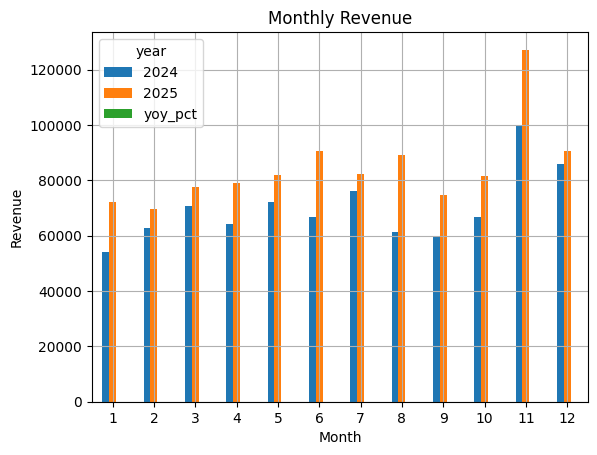

In [217]:
month.plot(kind='bar', title='Monthly Revenue', ylabel='Revenue', xlabel='Month')
plt.xticks(rotation=0)
plt.grid()
plt.savefig('chart1_monthly_revenue.png', dpi=300)
plt.show()



In [218]:
completed['category'] = completed['category'].str.strip().str.title()
cat_rev = completed.groupby(['category','year'])['revenue'].sum().unstack()
cat_rev

year,2024,2025
category,,
Bath,49884.59,58193.09
Bedding,122968.88,141352.38
Decor,125814.80,148552.69
Furniture,141549.39,177043.74
Kitchen,122232.49,153870.57
Lighting,105226.04,129357.03
Outdoor,116412.15,127685.15
Storage,57047.99,80930.02


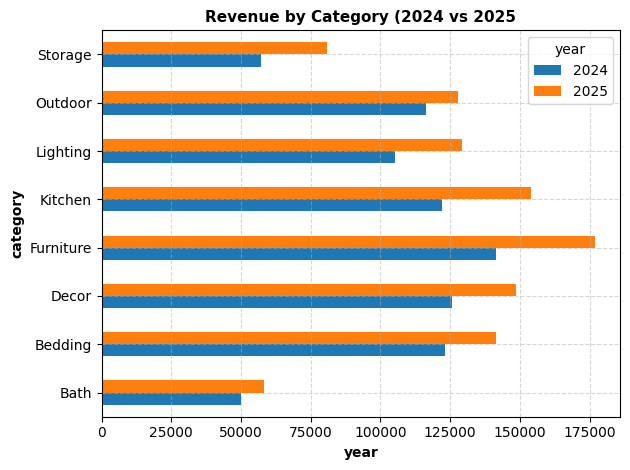

In [219]:
completed['category'] = completed['category'].str.strip().str.title()
cat_rev = completed.groupby(['category','year'])['revenue'].sum().unstack()

cat_rev.plot(kind = 'barh' ,ax=plt.gca())
plt.ylabel('category',fontweight = 'semibold')
plt.xlabel("year", fontweight = 'semibold')
plt.title("Revenue by Category (2024 vs 2025" , fontsize = 11,fontweight = 'bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('chart2_category_revenue.png', dpi=300)
plt.show()

### Acquisition Channel Performance Analysis
Let's analyze which customer acquisition channels are driving the most revenue, orders, and highest average order values (AOV).

In [220]:
# Calculate metrics by acquisition channel
channel_analysis = completed.groupby('acquisition_channel').agg(
    total_revenue=('revenue', 'sum'),
    unique_orders=('order_id', 'nunique'),
    total_quantity=('quantity', 'sum')
).reset_index()

# Calculate Average Order Value (AOV) per channel
channel_analysis['AOV'] = channel_analysis['total_revenue'] / channel_analysis['unique_orders']
channel_analysis = channel_analysis.sort_values(by='total_revenue', ascending=False).round(2)

display(channel_analysis)

,acquisition_channel,total_revenue,unique_orders,total_quantity,AOV
2,organic_search,762266.68,3433,7145,222.04
3,paid_search,286787.69,1251,2680,229.25
5,referral,271581.85,1239,2579,219.19
1,email,237606.61,1124,2321,211.39
4,paid_social,236371.09,1045,2215,226.19
0,affiliate,63507.08,305,605,208.22


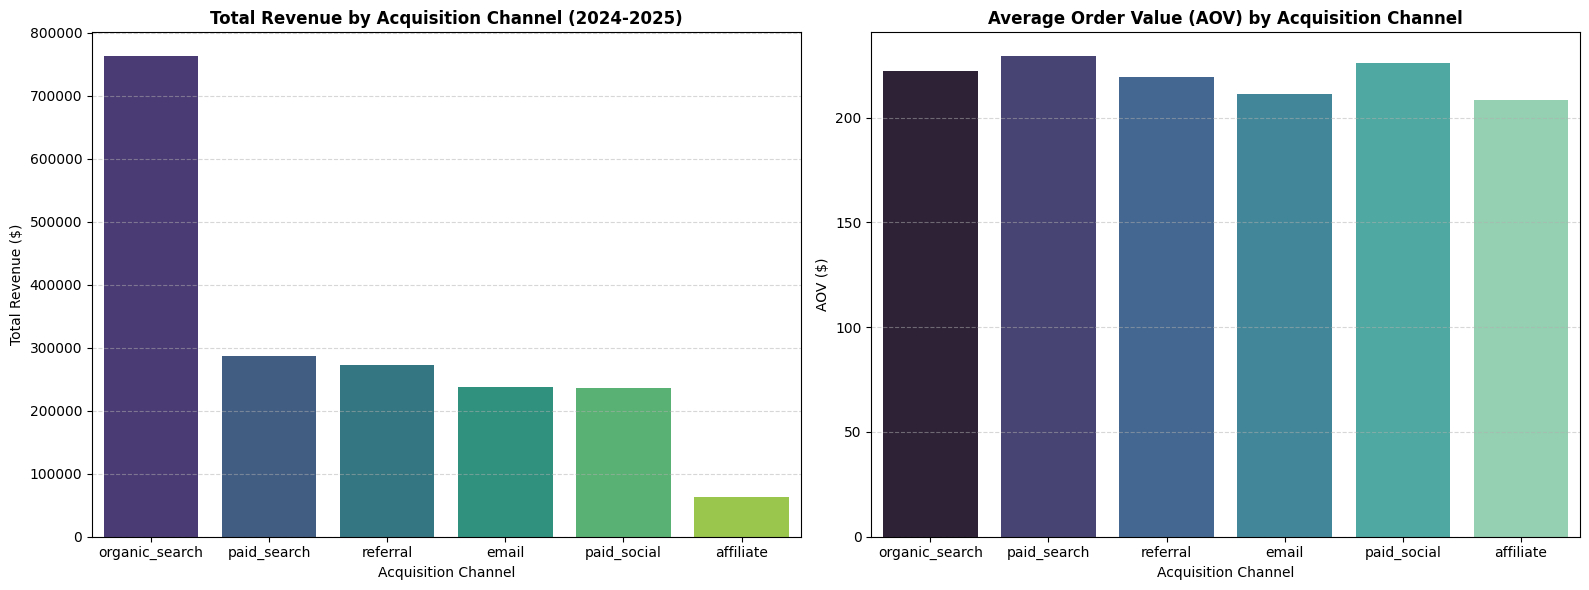

In [221]:
# Visualize Revenue and AOV by Acquisition Channel
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Total Revenue
sns.barplot(ax=axes[0], data=channel_analysis, x='acquisition_channel', y='total_revenue', palette='viridis', hue='acquisition_channel', legend=False)
axes[0].set_title('Total Revenue by Acquisition Channel (2024-2025)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Acquisition Channel')
axes[0].set_ylabel('Total Revenue ($)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot Average Order Value (AOV)
sns.barplot(ax=axes[1], data=channel_analysis, x='acquisition_channel', y='AOV', palette='mako', hue='acquisition_channel', legend=False)
axes[1].set_title('Average Order Value (AOV) by Acquisition Channel', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Acquisition Channel')
axes[1].set_ylabel('AOV ($)')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('chart3_channel_performance.png', dpi=300)
plt.show()

### Targeting Paid Search: Top Product Categories
To make sure our recommendation is highly targeted, we will analyze category revenue generated specifically by customers acquired through **Paid Search**.

In [222]:
# Filter completed orders to only include Paid Search customers
paid_search_orders = completed[completed['acquisition_channel'] == 'paid_search']

# Calculate revenue by product category within this channel
paid_search_cat_rev = paid_search_orders.groupby('category')['revenue'].sum().reset_index()
paid_search_cat_rev = paid_search_cat_rev.sort_values(by='revenue', ascending=False).round(2)

display(paid_search_cat_rev)

,category,revenue
3,Furniture,48499.95
1,Bedding,43266.51
2,Decor,40838.94
4,Kitchen,39966.83
5,Lighting,36881.47
6,Outdoor,36566.78
7,Storage,22688.44
0,Bath,18078.77


### Recommended Top 3 Product Categories for Paid Search Campaign

Based on the actual sales performance within the **Paid Search** segment, we recommend focusing your marketing spend on the following top 3 categories:

1. **Furniture** ($48,499.95)
  - Consistently the highest revenue driver in Paid Search with the largest overall volume.

2. **Bedding** ($43,266.51)
 - Strongly positioned in second place for customer conversions in this specific channel.

3. **Decor** ($40,838.94)
 - Follows closely as a high-margin, high-demand category perfect for search ad visuals.



# Executive Summary: Business Performance & Growth Outlook (2024 vs 2025)

### **Three Key Findings**
1. Solid Top-line Growth:

    Overall business revenue experienced strong double-digit growth, climbing **21%** from **$926.5k** in 2024 to **$1.12M** in 2025.




2. Furniture Dominance & Storage Acceleration:
    
    Furniture remains our highest-revenue product category overall (reaching **$177.0k** in 2025), while **Storage** represents our fastest-growing segment with an impressive YoY surge from $57.0k to **$80.9k**.


3. Organic Search is our Powerhouse Channel:

    Customer acquisition is heavily driven by **Organic Search**, which accounted for **$762.3k** (nearly 68% of total revenue). Meanwhile, **Paid Search** commands the highest Average Order Value (AOV) at **$227.43** per transaction, with **Furniture**, **Bedding**, and **Decor** generating the highest individual category revenues.

---

### **Two Recommendations for Next Year's Plan**
1. **Aggressive SEO & Content Retention:
    
    Since Organic Search brings in over two-thirds of total company sales, we must safeguard and grow this channel. Prioritize high-quality content marketing, product page SEO, and user-experience optimizations to maintain this core acquisition advantage.
2. **Targeted Campaigns on Paid Search High-Performers:
     
     Allocate paid search advertising budget primarily to **Furniture**, **Bedding**, and **Decor**. This capitalizes directly on our highest spend-per-transaction channel and concentrates your marketing dollars where conversion and transaction values are historically strongest.